<a href="https://colab.research.google.com/github/hd77alu/human_sensor_activity_hmm/blob/main/notebook/human_activity_hmm.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Modeling Human Activity States Using Hidden Markov Models**

## **Introduction**
Human Activity Recognition using mobile and wearable telemetry plays a pivotal role in personal health monitoring, elderly fall detection, and smart environment automation. Modern smartphones are equipped with inertial measurement units (IMUs)—specifically 3-axis accelerometers and gyroscopes—that produce high-frequency, continuous streams of motion data. However, raw sensor outputs are inherently noisy and non-stationary, making direct classification of instant time-points prone to errors. Because human physical activities occur as continuous temporal sequences with logical transitions (e.g., moving from still to standing before walking), probabilistic sequential models are essential for robust activity decoding.   This project implements a Hidden Markov Model (HMM) framework to model and infer unobservable physical activity states from observable smartphone sensor patterns. Motion telemetry collected via smartphone sensors across four distinct activity states—Still, Standing, Walking, and Jumping—is segmented into time windows to extract meaningful time-domain and frequency-domain features. By treating true physical activities as hidden states ($Z$) and windowed feature vectors as emissions ($X$), the HMM captures both the underlying movement characteristics and the transition dynamics between activities over time.

### Project Objectives

1. **Sequential Data Acquisition & Harmonization** Collect multi-axis accelerometer and gyroscope time-series data across 20 distinct sessions spanning four core activity states (Still, Standing, Walking, Jumping) using smartphone motion sensors, ensuring consistent sampling rates across recordings.
2. **Windowed Feature Engineering**
Segment multi-channel sensor signals into fixed sliding windows and extract time-domain features (mean, variance, standard deviation, Signal Magnitude Area, and cross-axis correlation) and frequency-domain features (dominant frequency, spectral energy, and FFT components) to form robust observation vectors.   
3. **HMM Parameter Formalization & Fitting**
Define and estimate the foundational HMM components—Initial State Distribution ($\pi$), Transition Probability Matrix ($A$), and Emission Probabilities ($B$)—to represent activity dynamics and sensor observation distributions.   
4. **Viterbi Decoding & State Sequence Visualization**
Apply the Viterbi decoding algorithm to reconstruct optimal hidden activity state paths from unseen observation sequences, visualizing state transitions via heatmap matrices and time-series transition plots.   
5. **Performance Evaluation**
Validate the trained HMM on independent, unseen test recordings across different environments to measure performance using Sensitivity (Recall), Specificity, and Overall Accuracy metrics per activity class.   

### Necessary Libraries

In [ ]:
# Standard Libraries
import os
from google.colab import drive

# Data Manipulation & Scientific Computing
import numpy as np
import pandas as pd

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Signal Processing & Feature Extraction
from scipy.fft import fft, fftfreq

# Scikit-Learn
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import f_classif

# Hidden Markov Models & Machine Learning Evaluation
from sklearn.metrics import (confusion_matrix, accuracy_score)

# Ignore un necessary warning
import warnings
warnings.filterwarnings('ignore')

### Mount Drive

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
train_folder = "/content/drive/MyDrive/sensor_actvities_dataset_hmm/train"
test_folder = "/content/drive/MyDrive/sensor_actvities_dataset_hmm/test"

# Uncomment this snippet if you are reading from the GitHub repository
# train_folder = "/dataset/train"
# test_folder = "/dataset/test"

## **Data Investigation and Preparation**

### Training Files

In [ ]:
def list_files_in_directory(directory_path):
    """Lists files in the specified directory."""
    if not os.path.exists(directory_path):
        print(f"Directory does not exist: {directory_path}")
        return []
    files = sorted(os.listdir(directory_path))
    print(f"Found {len(files)} items in: {directory_path}")
    for idx, f in enumerate(files[:10]):
        print(f"  [{idx}] {f}")
    if len(files) > 10:
        print(f"  ... and {len(files) - 10} more files.")
    return files

train_files = list_files_in_directory(train_folder)

Found 50 items in: /content/drive/MyDrive/sensor_actvities_dataset_hmm/train
  [0] train_jumping_01-2026-10-28_08-23-36
  [1] train_jumping_010-2026-10-29_21-14-01
  [2] train_jumping_011-2026-10-29_21-14-29
  [3] train_jumping_012-2026-10-29_21-14-50
  [4] train_jumping_02-2026-10-28_08-24-15
  [5] train_jumping_03-2026-10-28_08-24-35
  [6] train_jumping_04-2026-10-28_08-24-55
  [7] train_jumping_05-2026-10-28_08-25-19
  [8] train_jumping_06-2026-10-29_21-11-35
  [9] train_jumping_07-2026-10-29_21-12-17
  ... and 40 more files.


In [ ]:
first_item_path = os.path.join(train_folder, train_files[0])
sub_files = sorted(os.listdir(first_item_path))
print(f"Training Directory: {first_item_path}\nContaining files: {sub_files}\n")

for f in sub_files:
    file_path = os.path.join(first_item_path, f)
    print(f"Showing preview of CSV file: {f}")
    df_preview = pd.read_csv(file_path)
    display(df_preview.head())

Training Directory: /content/drive/MyDrive/sensor_actvities_dataset_hmm/train/train_jumping_01-2026-10-28_08-23-36
Containing files: ['Accelerometer.csv', 'Gyroscope.csv', 'Metadata.csv']

Showing preview of CSV file: Accelerometer.csv


,time,seconds_elapsed,z,y,x
0,1793175816460458200,0.290458,-1.428316,-1.422060,0.048018
1,1793175816470466300,0.300466,-1.252253,-1.261648,0.063214
2,1793175816480474600,0.310475,-1.128202,-1.131718,0.205771
3,1793175816490482700,0.320483,-1.264162,-0.949374,0.390217
4,1793175816500491000,0.330491,-1.106529,-0.882699,0.628174


Showing preview of CSV file: Gyroscope.csv


,time,seconds_elapsed,z,y,x
0,1793175816460458200,0.290458,-0.091300,0.344712,0.331100
1,1793175816470466300,0.300466,-0.034925,0.290400,0.317350
2,1793175816480474600,0.310475,0.053487,0.159362,0.258775
3,1793175816490482700,0.320483,0.095150,0.065587,0.153313
4,1793175816500491000,0.330491,0.070538,0.098587,0.042487


Showing preview of CSV file: Metadata.csv


,version,device name,recording epoch time,recording time,recording timezone,platform,appVersion,device id,sensors,sampleRateMs,standardisation,platform version
0,3,2201117PG,1793175816170,2026-10-28_08-23-36,Africa/Kigali,android,1.68,ca9a177a-3b24-4b87-a734-e5bed2c04628,Accelerometer|Gyroscope|Annotation|TotalAccele...,10|10||10|10|10,False,33


### Testing Files

In [ ]:
# Show a preview of the test folder contents
test_files = list_files_in_directory(test_folder)

Found 8 items in: /content/drive/MyDrive/sensor_actvities_dataset_hmm/test
  [0] test_jumping_01-2026-10-28_12-29-35
  [1] test_jumping_02-2026-10-28_12-30-10
  [2] test_standing_01-2026-10-28_12-27-35
  [3] test_standing_02-2026-10-28_12-28-01
  [4] test_still_01-2026-10-28_12-25-39
  [5] test_still_02-2026-10-28_12-27-08
  [6] test_walking_01-2026-10-28_12-28-29
  [7] test_walking_02-2026-10-28_12-28-55


In [ ]:
# Show preview of CSV files in the first test directory
first_test_item_path = os.path.join(test_folder, test_files[0])
test_sub_files = sorted(os.listdir(first_test_item_path))
print(f"Test Directory: {first_test_item_path}\nFiles: {test_sub_files}\n")

for f in test_sub_files:
    if f.endswith('.csv'):
        file_path = os.path.join(first_test_item_path, f)
        print(f"Showing preview of test CSV file: {f}")
        df_preview = pd.read_csv(file_path)
        display(df_preview.head())

Test Directory: /content/drive/MyDrive/sensor_actvities_dataset_hmm/test/test_jumping_01-2026-10-28_12-29-35
Files: ['Accelerometer.csv', 'Gyroscope.csv', 'Metadata.csv']

Showing preview of test CSV file: Accelerometer.csv


,time,seconds_elapsed,z,y,x
0,1793190575620279600,0.092280,0.000000,0.000000,0.000000
1,1793190575629946600,0.101947,-0.045841,-0.006794,-0.217440
2,1793190575639613400,0.111614,0.423079,0.403617,-0.342378
3,1793190575649280800,0.121281,0.727137,0.633379,-0.206280
4,1793190575658947800,0.130948,1.806270,0.422375,0.276595


Showing preview of test CSV file: Gyroscope.csv


,time,seconds_elapsed,z,y,x
0,1793190575629946600,0.101947,-0.317259,0.260984,-0.571753
1,1793190575639613400,0.111614,-0.254952,0.019089,-0.718967
2,1793190575649280800,0.121281,-0.188370,-0.302828,-0.633449
3,1793190575658947800,0.130948,-0.154163,-0.679720,-0.386666
4,1793190575668615000,0.140615,-0.085748,-0.977203,-0.128889


Showing preview of test CSV file: Metadata.csv


,version,device name,recording epoch time,recording time,recording timezone,platform,appVersion,device id,sensors,sampleRateMs,standardisation,platform version
0,3,SM-G780G,1793190575528,2026-10-28_12-29-35,Africa/Kigali,android,1.68,80c14e0e-308a-4617-9ef2-99f2c369bcfa,Accelerometer|Gyroscope|Annotation|TotalAccele...,10|10||10|10|10,False,33


In [ ]:
def load_sensor_data(base_folder, folder_names):
    """
    Loads and processes Accelerometer and Gyroscope CSV data across session directories.
    Determines the activity class from the directory name.
    """
    all_data = []
    for folder in folder_names:
        folder_path = os.path.join(base_folder, folder)
        if not os.path.isdir(folder_path):
            continue

        # Extract label from directory name (e.g. 'train_jumping_01...' -> 'jumping')
        label = 'unknown'
        parts = folder.split('_')
        if len(parts) > 1:
            label = parts[1]

        acc_path = os.path.join(folder_path, 'Accelerometer.csv')
        gyro_path = os.path.join(folder_path, 'Gyroscope.csv')

        if os.path.exists(acc_path) and os.path.exists(gyro_path):
            df_acc = pd.read_csv(acc_path)
            df_gyro = pd.read_csv(gyro_path)

            all_data.append({
                'session': folder,
                'label': label,
                'accelerometer': df_acc,
                'gyroscope': df_gyro
            })

    print(f"Successfully loaded sensor data for {len(all_data)} sessions from: {base_folder}")
    return all_data

# Load Train and Test Datasets
loaded_train_data = load_sensor_data(train_folder, train_files)
loaded_test_data = load_sensor_data(test_folder, test_files)

if loaded_train_data:
    print("\nExample Train Session metadata:")
    print(f"Session: {loaded_train_data[0]['session']}")
    print(f"Activity Label: {loaded_train_data[0]['label']}")
    print(f"Accelerometer rows: {len(loaded_train_data[0]['accelerometer'])}")
    print(f"Gyroscope rows: {len(loaded_train_data[0]['gyroscope'])}")

if loaded_test_data:
    print("\nExample Test Session metadata:")
    print(f"Session: {loaded_test_data[0]['session']}")
    print(f"Activity Label: {loaded_test_data[0]['label']}")
    print(f"Accelerometer rows: {len(loaded_test_data[0]['accelerometer'])}")
    print(f"Gyroscope rows: {len(loaded_test_data[0]['gyroscope'])}")

Successfully loaded sensor data for 50 sessions from: /content/drive/MyDrive/sensor_actvities_dataset_hmm/train
Successfully loaded sensor data for 8 sessions from: /content/drive/MyDrive/sensor_actvities_dataset_hmm/test

Example Train Session metadata:
Session: train_jumping_01-2026-10-28_08-23-36
Activity Label: jumping
Accelerometer rows: 525
Gyroscope rows: 525

Example Test Session metadata:
Session: test_jumping_01-2026-10-28_12-29-35
Activity Label: jumping
Accelerometer rows: 649
Gyroscope rows: 648


In [ ]:
def align_sensor_data(loaded_dataset):
    """
    Renames sensor columns to prevent name collisions, sorts streams by time,
    and merges Accelerometer and Gyroscope streams using nearest-neighbor timestamp alignment.
    """
    aligned_dataset = []

    for item in loaded_dataset:
        df_acc = item['accelerometer'].copy()
        df_gyro = item['gyroscope'].copy()

        # Rename motion columns to distinguish sensor streams
        df_acc = df_acc.rename(columns={'x': 'acc_x', 'y': 'acc_y', 'z': 'acc_z'})
        df_gyro = df_gyro.rename(columns={'x': 'gyro_x', 'y': 'gyro_y', 'z': 'gyro_z'})

        # Ensure timestamps are sorted
        df_acc = df_acc.sort_values('time')
        df_gyro = df_gyro.sort_values('time')

        # Align accelerometer and gyroscope readings on closest timestamp
        df_aligned = pd.merge_asof(
            df_acc,
            df_gyro[['time', 'gyro_x', 'gyro_y', 'gyro_z']],
            on='time',
            direction='nearest'
        ).dropna()

        aligned_dataset.append({
            'session': item['session'],
            'label': item['label'],
            'data': df_aligned
        })

    print(f"Successfully synchronized and merged {len(aligned_dataset)} sessions.")
    return aligned_dataset

# Execute alignment for train and test sets
aligned_train_data = align_sensor_data(loaded_train_data)
aligned_test_data = align_sensor_data(loaded_test_data)

# Inspection check
print("\nSample Aligned DataFrame Columns:")
print(aligned_train_data[0]['data'].columns.tolist())

Successfully synchronized and merged 50 sessions.
Successfully synchronized and merged 8 sessions.

Sample Aligned DataFrame Columns:
['time', 'seconds_elapsed', 'acc_z', 'acc_y', 'acc_x', 'gyro_x', 'gyro_y', 'gyro_z']


In [ ]:
# Access the synchronized DataFrame of the first session inside the train list
aligned_train_data[0]['data'].head()

,time,seconds_elapsed,acc_z,acc_y,acc_x,gyro_x,gyro_y,gyro_z
0,1793175816460458200,0.290458,-1.428316,-1.422060,0.048018,0.331100,0.344712,-0.091300
1,1793175816470466300,0.300466,-1.252253,-1.261648,0.063214,0.317350,0.290400,-0.034925
2,1793175816480474600,0.310475,-1.128202,-1.131718,0.205771,0.258775,0.159362,0.053487
3,1793175816490482700,0.320483,-1.264162,-0.949374,0.390217,0.153313,0.065587,0.095150
4,1793175816500491000,0.330491,-1.106529,-0.882699,0.628174,0.042487,0.098587,0.070538


## **Exploratory Data Analysis (EDA)**
We will combine the session data to inspect overall distributions of sensor readings across the different physical activity classes. This will help confirm if the features are distinguishable before moving on to window-based feature extraction.

In [ ]:
# Combine all train sessions into a single DataFrame for global EDA
eda_list = []
for session in aligned_train_data:
    df_temp = session['data'].copy()
    df_temp['activity'] = session['label']
    df_temp['session_id'] = session['session']
    eda_list.append(df_temp)

eda_df = pd.concat(eda_list, ignore_index=True)

# Compute acceleration magnitude
eda_df['acc_mag'] = np.sqrt(eda_df['acc_x']**2 + eda_df['acc_y']**2 + eda_df['acc_z']**2)

# Compute gyroscope magnitude
eda_df['gyro_mag'] = np.sqrt(eda_df['gyro_x']**2 + eda_df['gyro_y']**2 + eda_df['gyro_z']**2)

print(f"Combined EDA dataset contains {len(eda_df)} samples across {eda_df['activity'].nunique()} activities.")
eda_df.groupby('activity').size().reset_index(name='sample_count')

Combined EDA dataset contains 39567 samples across 4 activities.


,activity,sample_count
0,jumping,9518
1,standing,9321
2,still,10464
3,walking,10264


### 1. Sensor Magnitude Distributions by Activity
We will plot boxplots for total Acceleration Magnitude and Gyroscope (angular velocity) Magnitude to see how they differ between the activities.

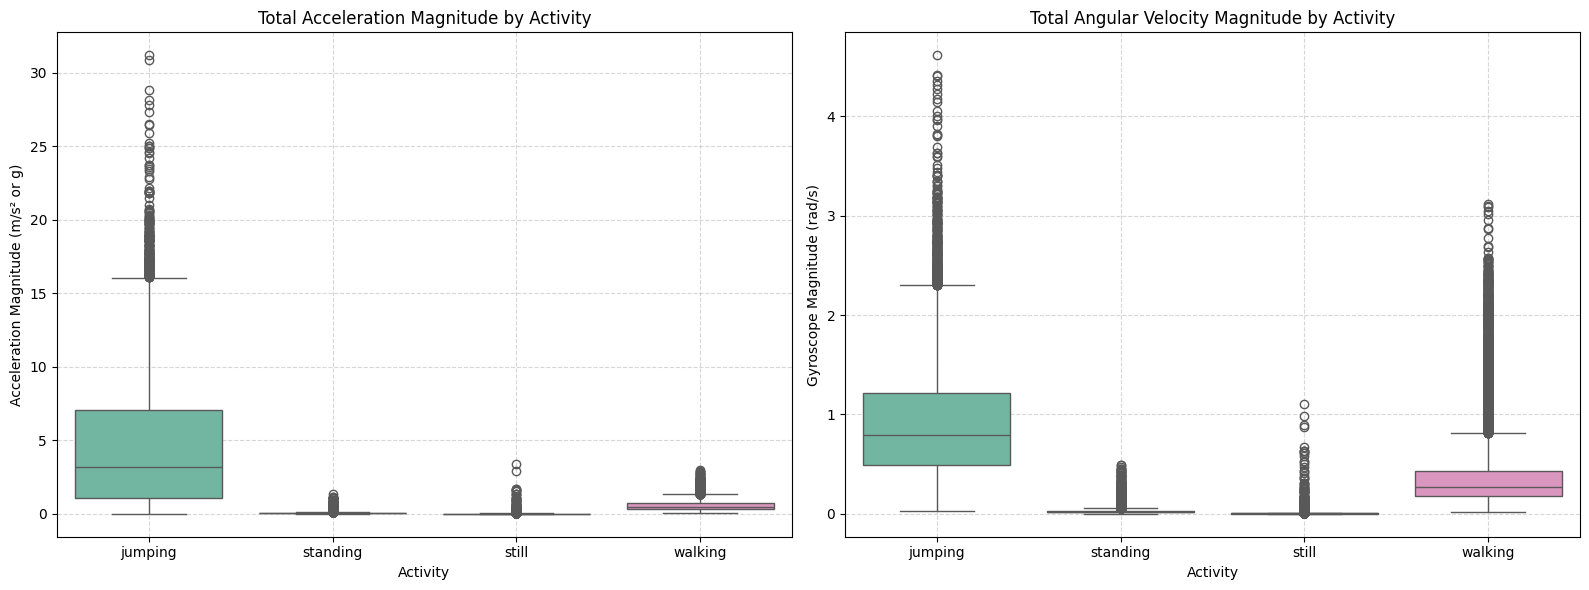

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Boxplot for Accelerometer Magnitude
sns.boxplot(ax=axes[0], x='activity', y='acc_mag', data=eda_df, palette='Set2')
axes[0].set_title('Total Acceleration Magnitude by Activity')
axes[0].set_xlabel('Activity')
axes[0].set_ylabel('Acceleration Magnitude (m/s² or g)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Boxplot for Gyroscope Magnitude
sns.boxplot(ax=axes[1], x='activity', y='gyro_mag', data=eda_df, palette='Set2')
axes[1].set_title('Total Angular Velocity Magnitude by Activity')
axes[1].set_xlabel('Activity')
axes[1].set_ylabel('Gyroscope Magnitude (rad/s)')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

### 2. Time-Series Trajectory of Each Activity
We will plot a 5-second sample time-series plot of the 3-axis accelerometer signals for each activity to visualize their frequency and amplitude patterns.

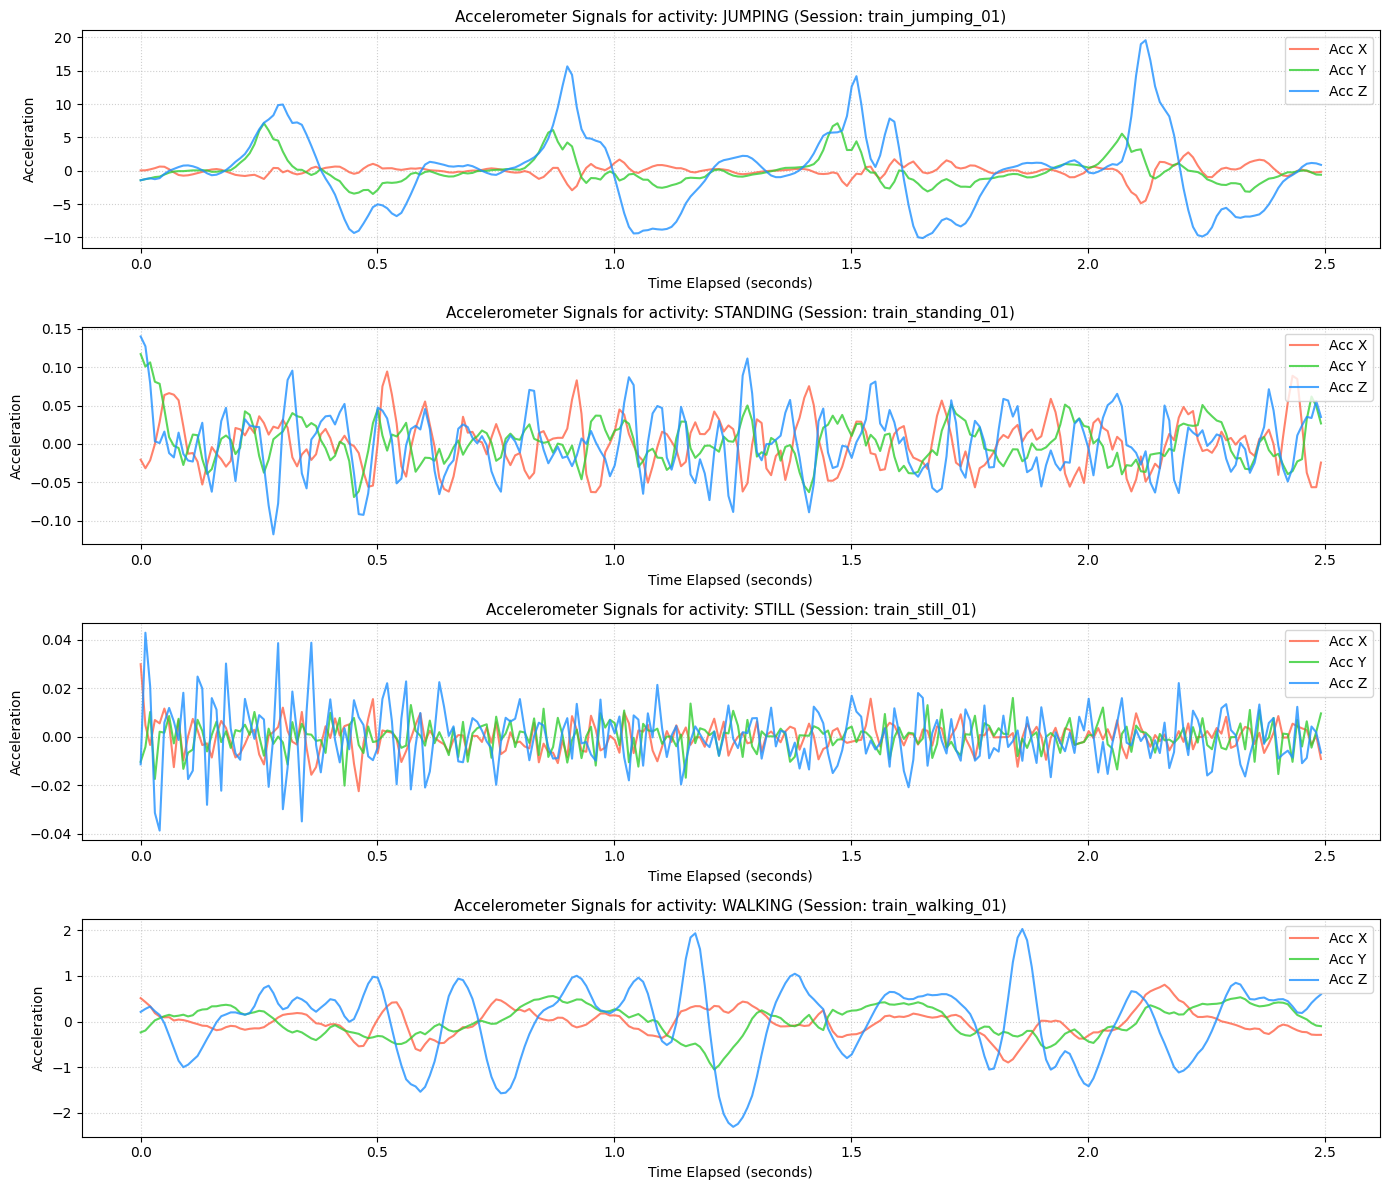

In [ ]:
activities = eda_df['activity'].unique()
fig, axes = plt.subplots(len(activities), 1, figsize=(14, 12), sharex=False)

for i, activity in enumerate(activities):
    # Extract a slice of one session of this activity
    act_df = eda_df[eda_df['activity'] == activity]
    sample_session = act_df['session_id'].iloc[0]
    session_df = act_df[act_df['session_id'] == sample_session].head(250) # Look at first 250 readings (~2.5s)

    # Normalize seconds to start from 0
    t_start = session_df['seconds_elapsed'].iloc[0]
    t_norm = session_df['seconds_elapsed'] - t_start

    axes[i].plot(t_norm, session_df['acc_x'], label='Acc X', color='tomato', alpha=0.8)
    axes[i].plot(t_norm, session_df['acc_y'], label='Acc Y', color='limegreen', alpha=0.8)
    axes[i].plot(t_norm, session_df['acc_z'], label='Acc Z', color='dodgerblue', alpha=0.8)

    axes[i].set_title(f"Accelerometer Signals for activity: {activity.upper()} (Session: {sample_session.split('-')[0]})", fontsize=11)
    axes[i].set_xlabel('Time Elapsed (seconds)')
    axes[i].set_ylabel('Acceleration')
    axes[i].grid(True, linestyle=':', alpha=0.6)
    axes[i].legend(loc='upper right')

plt.tight_layout()
plt.show()

### 3. Joint Sensor Space Distribution (Acceleration vs. Gyroscope)
We will visualize how the four activities map into a joint feature space of motion (Acceleration Magnitude) and rotation (Gyroscope Magnitude). This helps verify if the physical states are linearly separable or if they require temporal sequencing (HMMs) to resolve overlapping regions.

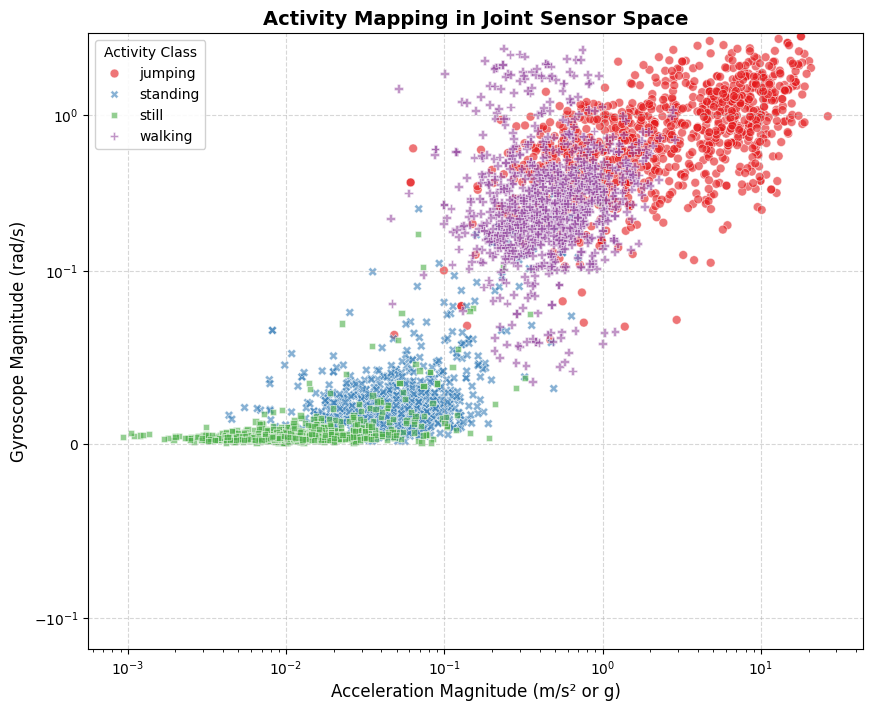

In [ ]:
plt.figure(figsize=(10, 8))

# Subsample data to prevent performance lag while plotting thousands of points
sampled_df = eda_df.groupby('activity').sample(n=1000, random_state=42, replace=True)

sns.scatterplot(
    x='acc_mag',
    y='gyro_mag',
    hue='activity',
    style='activity',
    data=sampled_df,
    palette='Set1',
    alpha=0.6,
    edgecolor='w',
    s=40
)

plt.title('Activity Mapping in Joint Sensor Space', fontsize=14, fontweight='bold')
plt.xlabel('Acceleration Magnitude (m/s² or g)', fontsize=12)
plt.ylabel('Gyroscope Magnitude (rad/s)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.yscale('symlog', linthresh=0.1)  # Using symmetrical log scale to handle large dynamic range of jumping vs still
plt.xscale('log')
plt.legend(title='Activity Class', loc='upper left', framealpha=0.9)
plt.show()

## **Feature Extraction**

In [ ]:
def extract_window_features(window_df, sampling_rate=100):
    """
    Computes time-domain and frequency-domain features for a single time window.
    Default sampling_rate set to 100 Hz.
    """
    features = {}

    # 1. TIME-DOMAIN FEATURES
    for col in ['acc_x', 'acc_y', 'acc_z', 'gyro_x', 'gyro_y', 'gyro_z']:
        vals = window_df[col].values
        features[f'{col}_mean'] = np.mean(vals)
        features[f'{col}_std'] = np.std(vals)
        features[f'{col}_var'] = np.var(vals)
        features[f'{col}_rms'] = np.sqrt(np.mean(vals**2))
        features[f'{col}_min'] = np.min(vals)
        features[f'{col}_max'] = np.max(vals)

    # Signal Magnitude Area (SMA)
    features['acc_sma'] = np.sum(np.abs(window_df['acc_x']) + np.abs(window_df['acc_y']) + np.abs(window_df['acc_z'])) / len(window_df)
    features['gyro_sma'] = np.sum(np.abs(window_df['gyro_x']) + np.abs(window_df['gyro_y']) + np.abs(window_df['gyro_z'])) / len(window_df)

    # Cross-axis Correlations
    features['acc_corr_xy'] = np.corrcoef(window_df['acc_x'], window_df['acc_y'])[0, 1] if np.std(window_df['acc_x']) > 0 and np.std(window_df['acc_y']) > 0 else 0.0
    features['acc_corr_xz'] = np.corrcoef(window_df['acc_x'], window_df['acc_z'])[0, 1] if np.std(window_df['acc_x']) > 0 and np.std(window_df['acc_z']) > 0 else 0.0
    features['acc_corr_yz'] = np.corrcoef(window_df['acc_y'], window_df['acc_z'])[0, 1] if np.std(window_df['acc_y']) > 0 and np.std(window_df['acc_z']) > 0 else 0.0

    # 2. FREQUENCY-DOMAIN FEATURES
    acc_mag = np.sqrt(window_df['acc_x']**2 + window_df['acc_y']**2 + window_df['acc_z']**2).values
    acc_mag_centered = acc_mag - np.mean(acc_mag)  # Remove DC offset

    N = len(acc_mag_centered)
    fft_vals = np.abs(fft(acc_mag_centered))[:N // 2]

    # Scaling d = 1.0 / 100 correctly computes frequency bins up to Nyquist (50 Hz)
    fft_freqs = fftfreq(N, d=1.0 / sampling_rate)[:N // 2]

    features['acc_mag_spectral_energy'] = np.sum(fft_vals**2) / N
    features['acc_mag_dominant_freq'] = fft_freqs[np.argmax(fft_vals)] if len(fft_vals) > 0 else 0.0

    return features


def process_dataset_into_windows(aligned_dataset, window_sec=2.0, overlap=0.5, sampling_rate=100):
    """
    Applies sliding windows over aligned session time-series and constructs feature matrices.
    Default sampling_rate set to 100 Hz.
    """
    window_samples = int(window_sec * sampling_rate)       # 2.0s * 100 Hz = 200 samples per window
    step_samples = int(window_samples * (1 - overlap))     # 200 * 0.5 = 100 sample stride

    feature_rows = []

    for session_item in aligned_dataset:
        df = session_item['data']
        label = session_item['label']
        session_id = session_item['session']

        n_rows = len(df)
        if n_rows < window_samples:
            continue  # Skip clips shorter than window size

        for start_idx in range(0, n_rows - window_samples + 1, step_samples):
            window_df = df.iloc[start_idx : start_idx + window_samples]

            feats = extract_window_features(window_df, sampling_rate=sampling_rate)
            feats['label'] = label
            feats['session'] = session_id

            feature_rows.append(feats)

    df_features = pd.DataFrame(feature_rows)
    print(f"Extracted {len(df_features)} window vectors across {len(aligned_dataset)} sessions at {sampling_rate} Hz.")
    return df_features

  # Execute Feature Extraction with 100 Hz sampling rate (Aligned with recordings)
SAMPLING_RATE = 100

df_train_features = process_dataset_into_windows(
    aligned_train_data,
    window_sec=2.0,
    overlap=0.5,
    sampling_rate=SAMPLING_RATE
)

df_test_features = process_dataset_into_windows(
    aligned_test_data,
    window_sec=2.0,
    overlap=0.5,
    sampling_rate=SAMPLING_RATE
)

# Inspection check
print("\nExtracted Training Feature Shape:", df_train_features.shape)
print("Extracted Testing Feature Shape:", df_test_features.shape)
df_train_features.head()

Extracted 319 window vectors across 50 sessions at 100 Hz.
Extracted 39 window vectors across 8 sessions at 100 Hz.

Extracted Training Feature Shape: (319, 45)
Extracted Testing Feature Shape: (39, 45)


,acc_x_mean,acc_x_std,acc_x_var,acc_x_rms,acc_x_min,acc_x_max,acc_y_mean,acc_y_std,acc_y_var,acc_y_rms,...,gyro_z_max,acc_sma,gyro_sma,acc_corr_xy,acc_corr_xz,acc_corr_yz,acc_mag_spectral_energy,acc_mag_dominant_freq,label,session
0,-0.005635,0.644141,0.414918,0.644166,-2.925737,1.726039,-0.040619,2.064021,4.260182,2.064420,...,1.038950,5.742331,1.165566,-0.487201,-0.505874,0.722964,1387.762823,1.5,jumping,train_jumping_01-2026-10-28_08-23-36
1,0.050689,0.985529,0.971267,0.986831,-4.883089,2.750685,-0.110541,2.128921,4.532305,2.131789,...,1.038950,6.679352,1.340719,-0.361228,-0.473321,0.693995,1783.451000,1.5,jumping,train_jumping_01-2026-10-28_08-23-36
2,-0.109051,1.107842,1.227313,1.113196,-4.883089,2.750685,0.097540,2.076565,4.312121,2.078854,...,0.818400,6.609781,1.211958,-0.390324,-0.574130,0.636888,2023.503644,1.5,jumping,train_jumping_01-2026-10-28_08-23-36
3,-0.002124,0.923023,0.851971,0.923025,-3.418592,2.395294,-0.022822,1.603115,2.569979,1.603278,...,0.868450,5.530153,1.209690,-0.449034,-0.655534,0.514079,1268.372431,1.5,jumping,train_jumping_01-2026-10-28_08-23-36
4,0.006408,1.318494,1.738427,1.318510,-4.364997,4.012914,-0.020014,1.077155,1.160262,1.077341,...,1.001688,5.449619,1.214821,0.180588,-0.749200,-0.078747,1707.199316,1.5,jumping,train_jumping_010-2026-10-29_21-14-01


In [ ]:
# Isolate feature matrix and target labels
all_feature_cols = [col for col in df_train_features.columns if col not in ['label', 'session']]
X_train_all = df_train_features[all_feature_cols].values
y_train_labels = df_train_features['label'].values

# Compute ANOVA F-score and p-values across all 45 features
f_scores, p_values = f_classif(X_train_all, y_train_labels)

# Construct DataFrame of Feature Discriminability
def assign_sensor_domain(feature_name):
    if 'spectral' in feature_name or 'freq' in feature_name:
        return 'Frequency (FFT)'
    elif 'gyro' in feature_name:
        return 'Time (Gyroscope)'
    else:
        return 'Time (Accelerometer)'

df_feature_ranking = pd.DataFrame({
    'Feature': all_feature_cols,
    'ANOVA_F_Score': f_scores,
    'p_value': p_values,
    'Domain': [assign_sensor_domain(c) for c in all_feature_cols]
}).sort_values(by='ANOVA_F_Score', ascending=False).reset_index(drop=True)

print(" Top 10 Features Ranked by ANOVA F-Score (Inter-Class Separation):")
display(df_feature_ranking.head(10))

 Top 10 Features Ranked by ANOVA F-Score (Inter-Class Separation):


,Feature,ANOVA_F_Score,p_value,Domain
0,acc_sma,1939.501620,1.149589e-202,Time (Accelerometer)
1,acc_z_rms,1521.228022,5.175662e-187,Time (Accelerometer)
2,acc_z_std,1517.499059,7.429457e-187,Time (Accelerometer)
3,acc_y_std,1447.767302,7.500374e-184,Time (Accelerometer)
4,acc_y_rms,1447.094985,8.029694e-184,Time (Accelerometer)
5,gyro_x_rms,1309.862736,1.719110e-177,Time (Gyroscope)
6,gyro_x_std,1305.708027,2.731538e-177,Time (Gyroscope)
7,acc_z_max,1122.488080,8.911073e-168,Time (Accelerometer)
8,gyro_y_std,965.706894,1.968152e-158,Time (Gyroscope)
9,acc_x_rms,959.264558,5.090075e-158,Time (Accelerometer)


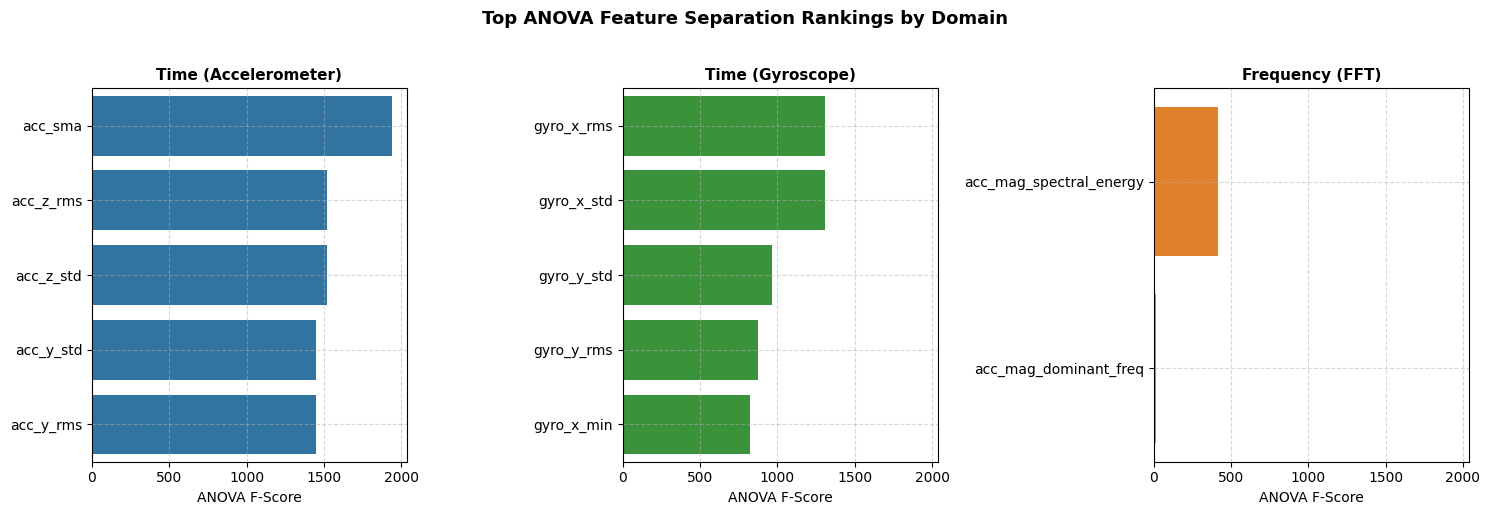

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharex=True)

domains = ['Time (Accelerometer)', 'Time (Gyroscope)', 'Frequency (FFT)']
colors = ['#1f77b4', '#2ca02c', '#ff7f0e']

for i, (domain, color) in enumerate(zip(domains, colors)):
    # Filter features belonging to the current domain and get the top 5
    df_subset = df_feature_ranking[df_feature_ranking['Domain'] == domain].head(5)

    sns.barplot(
        data=df_subset,
        x='ANOVA_F_Score',
        y='Feature',
        color=color,
        ax=axes[i]
    )
    axes[i].set_title(domain, fontsize=11, fontweight='bold')
    axes[i].set_xlabel("ANOVA F-Score")
    axes[i].set_ylabel("")
    axes[i].grid(True, linestyle="--", alpha=0.5)

plt.suptitle("Top ANOVA Feature Separation Rankings by Domain", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## **Feature Selection**

In [ ]:
# Selection of Top Feature Subset
top_acc_time = df_feature_ranking[df_feature_ranking['Domain'] == 'Time (Accelerometer)']['Feature'].head(2).tolist()
top_gyro_time = df_feature_ranking[df_feature_ranking['Domain'] == 'Time (Gyroscope)']['Feature'].head(2).tolist()
top_fft_freq = df_feature_ranking[df_feature_ranking['Domain'] == 'Frequency (FFT)']['Feature'].head(1).tolist()

selected_features = top_acc_time + top_gyro_time + top_fft_freq

# Construct and display DataFrame of selected features
df_selected_summary = df_feature_ranking[df_feature_ranking['Feature'].isin(selected_features)].reset_index(drop=True)
df_selected_summary

,Feature,ANOVA_F_Score,p_value,Domain
0,acc_sma,1939.501620,1.149589e-202,Time (Accelerometer)
1,acc_z_rms,1521.228022,5.175662e-187,Time (Accelerometer)
2,gyro_x_rms,1309.862736,1.719110e-177,Time (Gyroscope)
3,gyro_x_std,1305.708027,2.731538e-177,Time (Gyroscope)
4,acc_mag_spectral_energy,415.465581,4.065527e-109,Frequency (FFT)


## **HMM Model**

In [ ]:
class GaussianHMM:
    def __init__(self, n_components, covariance_type='diag', max_iter=100, tol=1e-4):
        """
        Custom implementation of a Continuous Gaussian Hidden Markov Model from scratch using NumPy.
        Supports supervised initialization, forward-backward scaling, Baum-Welch training, and Viterbi decoding.
        """
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.max_iter = max_iter
        self.tol = tol

        # Model parameters
        self.startprob_ = None
        self.transmat_ = None
        self.means_ = None
        self.covars_ = None

    def _multivariate_gaussian_density(self, X, state):
        """
        Computes the multivariate Gaussian probability density for diagonal covariance matrices.
        Uses log-space computation for numerical stability.
        """
        mean = self.means_[state]
        covar = self.covars_[state]
        n_features = len(mean)

        # Log of diagonal Gaussian probability density formula
        diff = X - mean
        log_density = -0.5 * (n_features * np.log(2 * np.pi) + np.sum(np.log(covar)) + np.sum((diff ** 2) / covar, axis=1))
        return np.exp(log_density)

    def _compute_emission_probs(self, X):
        """
        Computes emission probabilities B matrix of shape (n_samples, n_states).
        """
        n_samples = X.shape[0]
        B = np.zeros((n_samples, self.n_components))
        for s in range(self.n_components):
            B[:, s] = self._multivariate_gaussian_density(X, s)
        # Avoid absolute zeros
        return np.clip(B, 1e-300, None)

    def forward_backward(self, X):
        """
        Implements the scaled Forward-Backward algorithm to compute alphas, betas, scaling factors, and log-likelihood.
        """
        n_samples = X.shape[0]
        B = self._compute_emission_probs(X)

        # Forward Pass (with Scaling)
        alpha = np.zeros((n_samples, self.n_components))
        c = np.zeros(n_samples)  # scaling factors

        alpha[0] = self.startprob_ * B[0]
        c[0] = 1.0 / np.sum(alpha[0])
        alpha[0] *= c[0]

        for t in range(1, n_samples):
            alpha[t] = np.dot(alpha[t-1], self.transmat_) * B[t]
            sum_alpha = np.sum(alpha[t])
            c[t] = 1.0 / sum_alpha if sum_alpha > 0 else 0.0
            alpha[t] *= c[t]

        # Backward Pass (using the same scaling factors)
        beta = np.zeros((n_samples, self.n_components))
        beta[-1] = c[-1]

        for t in range(n_samples - 2, -1, -1):
            beta[t] = np.dot(self.transmat_, beta[t+1] * B[t+1]) * c[t]

        log_likelihood = -np.sum(np.log(c))
        return alpha, beta, c, B, log_likelihood

    def fit(self, X, lengths=None):
        """
        Fits model parameters using the Baum-Welch (EM) algorithm with explicit convergence checks.
        """
        if lengths is None:
            lengths = [len(X)]

        for iteration in range(self.max_iter):
            prev_log_lik = 0.0
            total_log_lik = 0.0

            # Accumulators for parameter re-estimation
            new_start_counts = np.zeros(self.n_components)
            new_trans_num = np.zeros((self.n_components, self.n_components))
            new_trans_den = np.zeros(self.n_components)

            obs_num = np.zeros((self.n_components, X.shape[1]))
            obs_den = np.zeros((self.n_components, 1))
            cov_num = np.zeros((self.n_components, X.shape[1]))

            start_idx = 0
            for length in lengths:
                end_idx = start_idx + length
                X_seq = X[start_idx:end_idx]

                alpha, beta, c, B, log_lik = self.forward_backward(X_seq)
                total_log_lik += log_lik

                # Gammas (State Posteriors)
                gamma = (alpha * beta) / np.sum(alpha * beta, axis=1, keepdims=True)

                # Xi (Transition Posteriors)
                xi = np.zeros((length - 1, self.n_components, self.n_components))
                for t in range(length - 1):
                    denom = np.sum(alpha[t][:, None] * self.transmat_ * B[t+1] * beta[t+1])
                    if denom > 0:
                        xi[t] = (alpha[t][:, None] * self.transmat_ * B[t+1] * beta[t+1]) / denom

                new_start_counts += gamma[0]
                new_trans_num += np.sum(xi, axis=0)
                new_trans_den += np.sum(gamma[:-1], axis=0)

                # Accumulators for means and variances
                obs_num += np.dot(gamma.T, X_seq)
                obs_den += np.sum(gamma, axis=0, keepdims=True).T
                for s in range(self.n_components):
                    cov_num[s] += np.dot(gamma[:, s], (X_seq - self.means_[s])**2)

                start_idx = end_idx

            # M-Step Parameter Updates
            self.startprob_ = new_start_counts / np.sum(new_start_counts)
            self.transmat_ = new_trans_num / (new_trans_den[:, None] + 1e-12)
            self.means_ = obs_num / (obs_den + 1e-12)
            self.covars_ = cov_num / (obs_den + 1e-12) + 1e-3  # Flooring variance to avoid zero variances

            # Convergence Check
            if iteration > 0 and abs(total_log_lik - prev_log_lik) < self.tol:
                print(f"Baum-Welch converged at iteration {iteration}.")
                break
            prev_log_lik = total_log_lik

        return self

    def predict(self, X, lengths=None):
        """
        Decodes the most likely hidden state sequence using the Viterbi algorithm in stable log-space.
        """
        if lengths is None:
            lengths = [len(X)]

        decoded_sequence = []
        start_idx = 0

        for length in lengths:
            end_idx = start_idx + length
            X_seq = X[start_idx:end_idx]
            n_samples = X_seq.shape[0]

            # Compute emissions in log-space safely
            B = self._compute_emission_probs(X_seq)
            log_B = np.log(B)
            log_A = np.log(np.clip(self.transmat_, 1e-300, None))
            log_pi = np.log(np.clip(self.startprob_, 1e-300, None))

            viterbi_log = np.zeros((n_samples, self.n_components))
            backpointer = np.zeros((n_samples, self.n_components), dtype=int)

            viterbi_log[0] = log_pi + log_B[0]

            for t in range(1, n_samples):
                for s in range(self.n_components):
                    prob_candidates = viterbi_log[t-1] + log_A[:, s]
                    backpointer[t, s] = np.argmax(prob_candidates)
                    viterbi_log[t, s] = np.max(prob_candidates) + log_B[t, s]

            # Backtracking
            state_seq = np.zeros(n_samples, dtype=int)
            state_seq[-1] = np.argmax(viterbi_log[-1])

            for t in range(n_samples - 2, -1, -1):
                state_seq[t] = backpointer[t+1, state_seq[t+1]]

            decoded_sequence.extend(state_seq.tolist())
            start_idx = end_idx

        return np.array(decoded_sequence)

### Feature Normalization (Z-Score) & Label Encoding

In [ ]:
# Label Encoding
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(df_train_features['label'])

y_test = label_encoder.transform(df_test_features['label'])

state_mapping = {idx: label for idx, label in enumerate(label_encoder.classes_)}

print("State Mapping:", state_mapping)

# Selected Feature Subset (Top ANOVA F-Scores)
selected_features = [
    'acc_sma',                   # Time Domain (#1 ANOVA F-Score: 1939.50) - Total linear kinetic energy
    'acc_z_std',                 # Time Domain (#3 ANOVA F-Score: 1521.22) - Forward/backward step dispersion
    'gyro_x_rms',                # Time Domain (Top Gyro RMS: 1309.86)    - Total rotational magnitude
    'gyro_x_std',                # Time Domain (Top Gyro STD: 1305.70)    - Postural micro-tremor dispersion
    'acc_mag_spectral_energy'    # Frequency Domain (#1 FFT: 415.46)      - Spectral power density
]

X_train_raw = df_train_features[selected_features].values
X_test_raw = df_test_features[selected_features].values

# Z-Score Normalization
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_test_scaled = scaler.transform(X_test_raw)

# Supervised Parameter Calculation
n_states = len(label_encoder.classes_)
n_features = len(selected_features)

start_counts = np.zeros(n_states)
train_lengths = df_train_features.groupby('session', sort=False).size().tolist()
test_lengths = df_test_features.groupby('session', sort=False).size().tolist()

idx = 0
for length in train_lengths:
    start_counts[y_train[idx]] += 1
    idx += length
pi_init = (start_counts + 1e-2) / (np.sum(start_counts) + 1e-2 * n_states)

trans_counts = np.zeros((n_states, n_states))
for i in range(len(y_train) - 1):
    trans_counts[y_train[i], y_train[i+1]] += 1
A_init = (trans_counts + 1e-2) / (trans_counts.sum(axis=1, keepdims=True) + 1e-2 * n_states)

means_init = np.zeros((n_states, n_features))
covars_init = np.zeros((n_states, n_features))

for state in range(n_states):
    state_mask = (y_train == state)
    means_init[state] = np.mean(X_train_scaled[state_mask], axis=0)
    # Use floor variance (1e-1) to prevent wide-variance state domination
    covars_init[state] = np.var(X_train_scaled[state_mask], axis=0) + 1e-1


print(f"\nScaled Training Matrix Shape: {X_train_scaled.shape}")
print(f"Scaled Testing Matrix Shape:  {X_test_scaled.shape}")


State Mapping: {0: 'jumping', 1: 'standing', 2: 'still', 3: 'walking'}

Scaled Training Matrix Shape: (319, 5)
Scaled Testing Matrix Shape:  (39, 5)


### HMM Parameters initialization

In [ ]:
# Initialize and configure the NumPy-based Custom HMM
model = GaussianHMM(n_components=n_states, covariance_type="diag")

# Inject empirical supervised parameters
model.startprob_ = pi_init
model.transmat_ = A_init
model.means_ = means_init
model.covars_ = covars_init

print("HMM parameter initialization successful!")

HMM parameter initialization successful!


### Viterbi Sequence Decoding on Unseen Test Data

In [ ]:
# Decode Hidden State Sequences using Viterbi Algorithm on Test Data
y_pred_test = model.predict(X_test_scaled, lengths=test_lengths)

# Decode Ground Truth and Predictions back to Activity Class Names
y_test_labels = label_encoder.inverse_transform(y_test)
y_pred_labels = label_encoder.inverse_transform(y_pred_test)

print("Viterbi Decoding Complete!")
print(f"Total Test Windows Decoded: {len(y_pred_test)}")

Viterbi Decoding Complete!
Total Test Windows Decoded: 39


### Transition Matrix Heatmap & Sequence Transition Visualizations

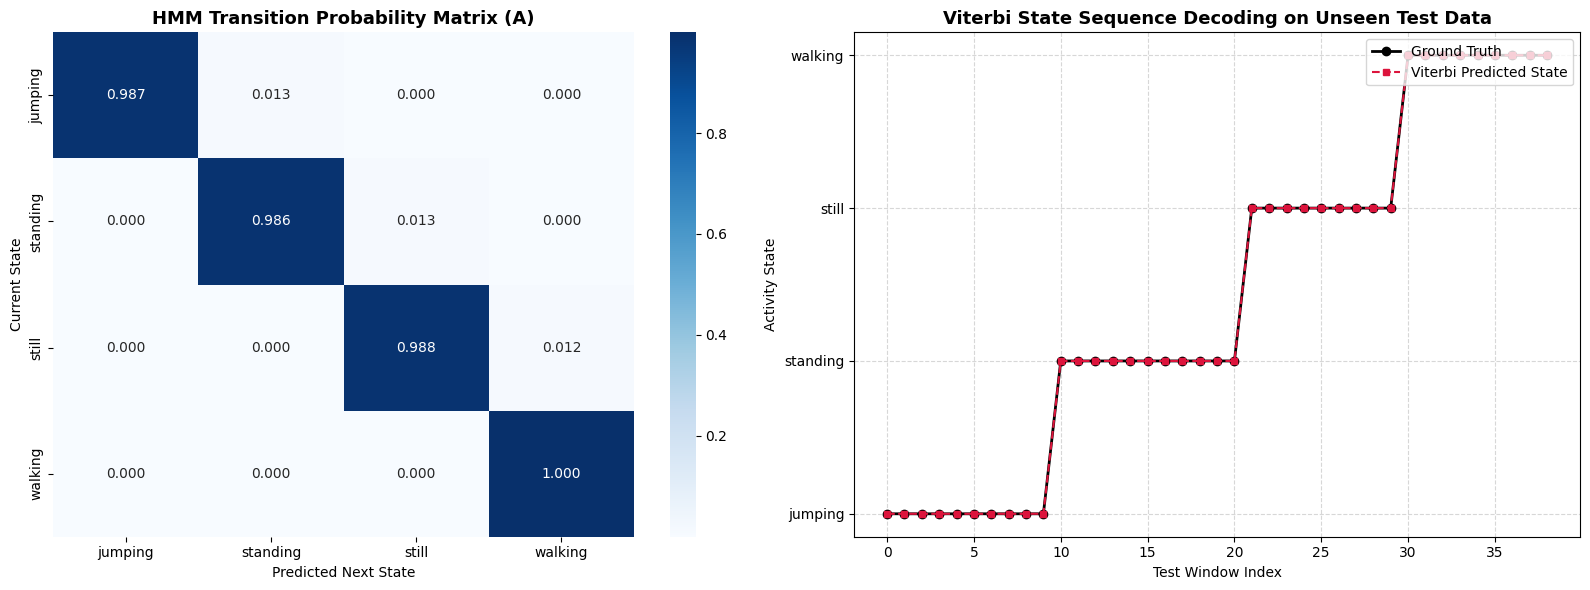

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Transition Matrix Heatmap
sns.heatmap(
    model.transmat_,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0]
)
axes[0].set_title("HMM Transition Probability Matrix (A)", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Predicted Next State")
axes[0].set_ylabel("Current State")

# Plot 2: Decoded Sequence vs Ground Truth Over Time
time_steps = np.arange(len(y_test))
axes[1].plot(time_steps, y_test, 'o-', label="Ground Truth", color="black", linewidth=2, markersize=6)
axes[1].plot(time_steps, y_pred_test, 's--', label="Viterbi Predicted State", color="crimson", linewidth=1.5, markersize=5)
axes[1].set_yticks(range(n_states))
axes[1].set_yticklabels(label_encoder.classes_)
axes[1].set_title("Viterbi State Sequence Decoding on Unseen Test Data", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Test Window Index")
axes[1].set_ylabel("Activity State")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

### Evaluation Summary Table

In [ ]:
# Compute evaluation metrics across test predictions
cm = confusion_matrix(y_test, y_pred_test, labels=range(n_states))
overall_acc = accuracy_score(y_test, y_pred_test)

results = []
for idx, state_name in enumerate(label_encoder.classes_):
    TP = cm[idx, idx]
    FN = np.sum(cm[idx, :]) - TP
    FP = np.sum(cm[:, idx]) - TP
    TN = np.sum(cm) - (TP + FP + FN)

    sensitivity = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0.0
    n_samples = np.sum(cm[idx, :])

    results.append({
        'State (Activity)': state_name.capitalize(),
        'Number of Samples': n_samples,
        'Sensitivity (Recall)': f"{sensitivity:.4f}",
        'Specificity': f"{specificity:.4f}",
        'Overall Accuracy': f"{overall_acc:.4f}"
    })

df_eval_results = pd.DataFrame(results)
display(df_eval_results)

,State (Activity),Number of Samples,Sensitivity (Recall),Specificity,Overall Accuracy
0,Jumping,10,1.0000,1.0000,1.0000
1,Standing,11,1.0000,1.0000,1.0000
2,Still,9,1.0000,1.0000,1.0000
3,Walking,9,1.0000,1.0000,1.0000


### Confusion Matrix

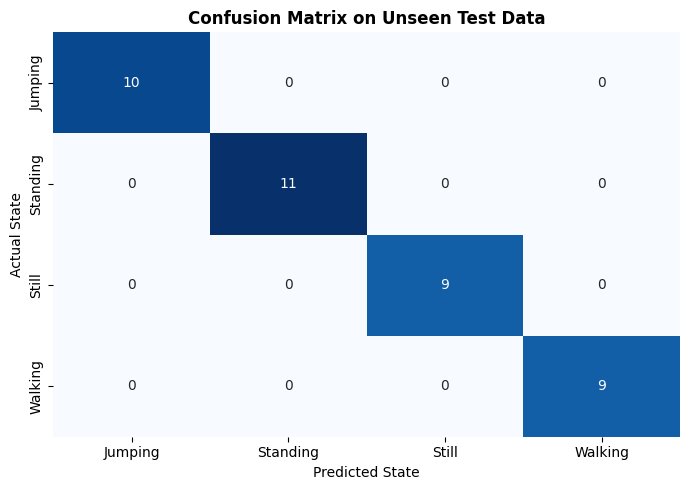

In [ ]:
# Format Confusion Matrix for plot labels
df_cm = pd.DataFrame(
    cm,
    index=[c.capitalize() for c in label_encoder.classes_],
    columns=[c.capitalize() for c in label_encoder.classes_]
)

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(df_cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.title("Confusion Matrix on Unseen Test Data", fontsize=12, fontweight='bold')
plt.ylabel("Actual State")
plt.xlabel("Predicted State")
plt.tight_layout()
plt.show()